<a href="https://colab.research.google.com/github/conganh1982006-dotcom/SE-ROCKET-SIMULATION/blob/Velocity-(No-drag)/numerical_no_drag_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [82]:
import numpy as np
import matplotlib.pyplot as plt

In [83]:
h = 0.02 #step
t = np.arange(0, 2 + h, h)
Y = np.zeros(len(t)) #create array (similar to Y[]={0} in C)
m = np.zeros(len(t))
v_improve = np.zeros(len(t))
m[0] = 1
Y[0] = 0 #intial value
ve=500
me=0.2
g=9.8
print(t)

[0.   0.02 0.04 0.06 0.08 0.1  0.12 0.14 0.16 0.18 0.2  0.22 0.24 0.26
 0.28 0.3  0.32 0.34 0.36 0.38 0.4  0.42 0.44 0.46 0.48 0.5  0.52 0.54
 0.56 0.58 0.6  0.62 0.64 0.66 0.68 0.7  0.72 0.74 0.76 0.78 0.8  0.82
 0.84 0.86 0.88 0.9  0.92 0.94 0.96 0.98 1.   1.02 1.04 1.06 1.08 1.1
 1.12 1.14 1.16 1.18 1.2  1.22 1.24 1.26 1.28 1.3  1.32 1.34 1.36 1.38
 1.4  1.42 1.44 1.46 1.48 1.5  1.52 1.54 1.56 1.58 1.6  1.62 1.64 1.66
 1.68 1.7  1.72 1.74 1.76 1.78 1.8  1.82 1.84 1.86 1.88 1.9  1.92 1.94
 1.96 1.98 2.  ]


In [84]:
v_exact = ve * np.log(m[0] / (m[0] - me * t)) - g * t #exact solution from
for i in range(len(t) - 1):
    m[i+1] = m[i] - 0.2 * h
    Y[i + 1] = Y[i] + h * ((ve * me) / m[i] - g)  #euler method
    v_improve[i+1] = Y[i] + h/2 * (((ve * me) / m[i] - g) + ((ve * me) / (m[i+1]) - g)) #improved euler method
print(Y)
print(v_exact)
print(v_improve)

[  0.           1.804        3.61603213   5.43616116   7.26445266
   9.10097298  10.94578931  12.79896964  14.66058281  16.53069851
  18.40938731  20.29672064  22.19277085  24.09761118  26.01131583
  27.93395989  29.86561947  31.80637161  33.75629435  35.71546677
  37.68396893  39.66188197  41.64928809  43.64627054  45.65291372
  47.6693031   49.69552532  51.73166818  53.77782064  55.83407289
  57.90051633  59.97724361  62.06434863  64.16192661  66.27007408
  68.38888889  70.51847029  72.65891888  74.81033672  76.97282729
  79.14649554  81.33144792  83.52779242  85.73563857  87.95509751
  90.18628197  92.42930636  94.68428675  96.95134094  99.23058847
 101.52215066 103.82615066 106.14271347 108.47196599 110.81403706
 113.16905747 115.53716003 117.91847962 120.3131532  122.72131986
 125.14312091 127.57869986 130.0282025  132.49177697 134.96957376
 137.46174581 139.96844851 142.48983981 145.02608025 147.577333
 150.14376394 152.72554171 155.3228378  157.93582657 160.56468532
 163.2095944

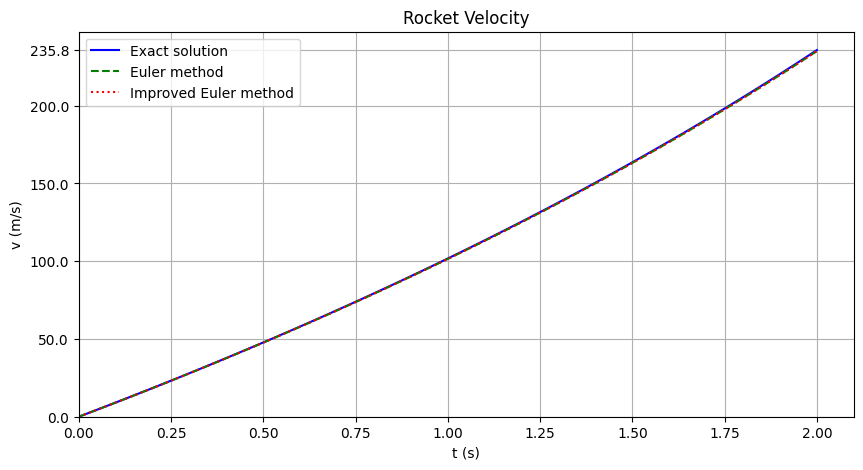

In [96]:
plt.subplots(figsize=(10,5))
plt.plot(t, v_exact, label='Exact solution', color ='blue')
plt.plot(t, Y, label='Euler method', linestyle='--', color='green')
plt.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='red')

#max value
max_y = max(np.max(Y), np.max(v_exact), np.max(v_improve))
ticks = [t for t in plt.yticks()[0] if t < max_y]
ticks.append(max_y)
plt.yticks(ticks)

plt.ylim(bottom=0)
plt.xlim(left=0)

plt.title('Rocket Velocity')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()

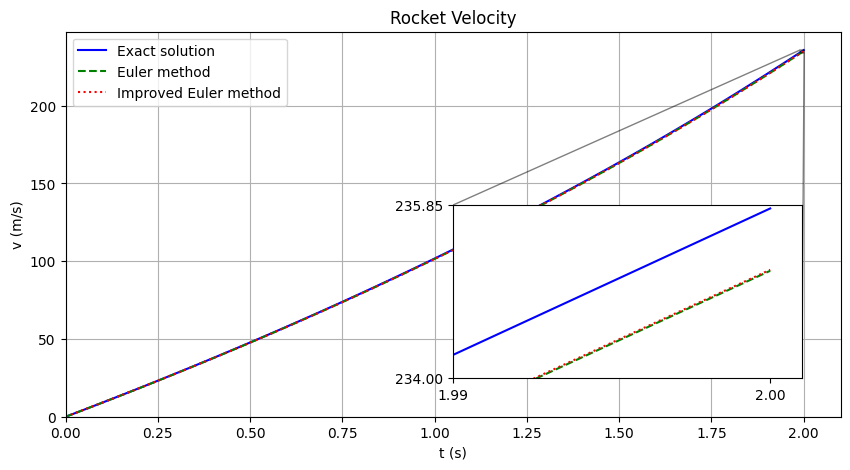

In [95]:

#zoom in
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(t, v_exact, label="Exact solution", color="blue")
ax.plot(t, Y, label="Euler method", linestyle="--", color="green")
ax.plot(t, v_improve, label="Improved Euler method", linestyle=":", color="red")
x1, x2, y1, y2 = 1.995, 2.001, 234, 235.82
axins = ax.inset_axes([0.5, 0.1, 0.45, 0.45], xlim=(x1, x2), ylim=(y1, y2))

plt.ylim(bottom=0)
plt.xlim(left=0)

axins.plot(t, v_exact, label='Exact solution', color ='blue')
axins.plot(t, Y, label='Euler method', linestyle='--', color='green')
axins.plot(t, v_improve, label ='Improved Euler method', linestyle='dotted', color='red')
axins.set_xticks([1.99, 2.0])
axins.set_yticks([234, 235.85])

ax.indicate_inset_zoom(axins, edgecolor="black")


plt.title('Rocket Velocity')
plt.xlabel('t (s)')
plt.ylabel('v (m/s)')
plt.grid(True)
plt.legend()
plt.show()